AGRICULTURAL DATA
  Zone  Soil_Moisture  Temperature  Humidity  Rainfall  Target_Min  Target_Max
Zone 1             18           32        45         1          25          35
Zone 2             22           30        55         2          25          35
Zone 3             15           35        40         0          25          35
Zone 4             28           29        65         3          25          35
Zone 5             20           33        50         1          25          35

STARTING CUCKOO SEARCH OPTIMIZATION

Iteration: 50 | Best Fitness: 60601.5097
Iteration: 100 | Best Fitness: 60598.1379
Iteration: 150 | Best Fitness: 60598.1379
Iteration: 200 | Best Fitness: 60598.1379
Iteration: 250 | Best Fitness: 60598.1379
Iteration: 300 | Best Fitness: 60598.1379

SMART IRRIGATION OPTIMIZATION RESULTS

  Zone  Initial Moisture (%)  Temperature (C)  Humidity (%)  Rainfall (mm)  ET (mm)  Optimized Water (mm)  Predicted Moisture (%)
Zone 1                    18               32    

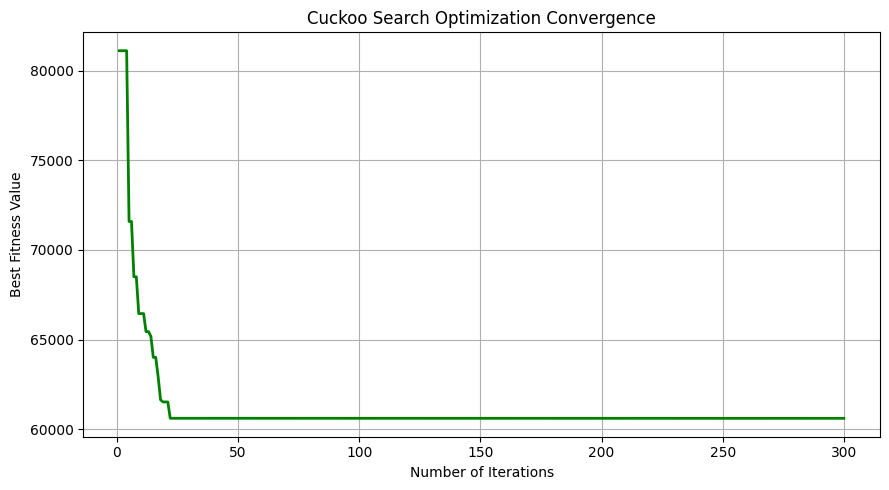

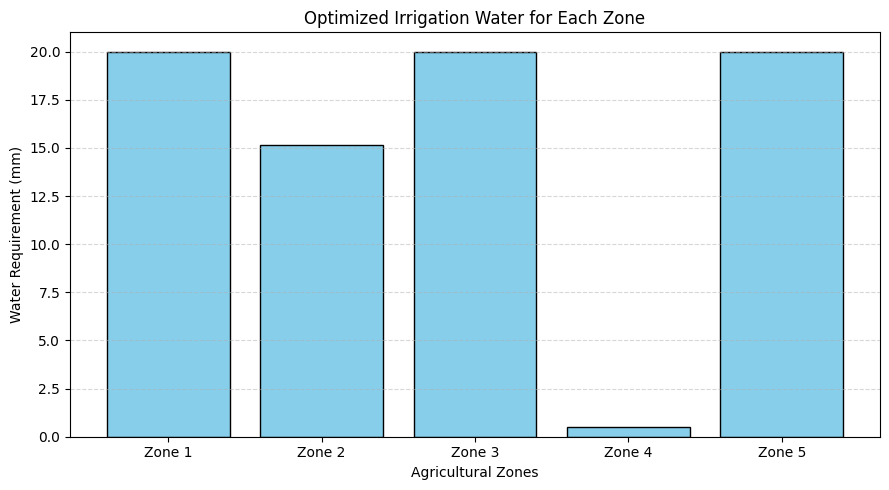

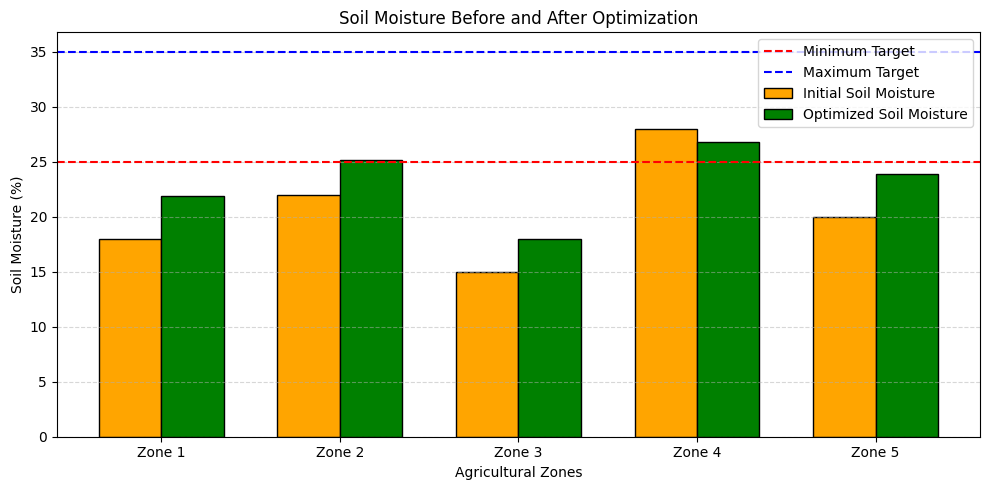


PROJECT CONCLUSION
Cuckoo Search Optimization completed successfully.
The algorithm calculated irrigation quantities for all agricultural zones.
The objective is to minimize water consumption while maintaining soil moisture within target limits.
Total optimized water: 75.64 mm


In [7]:
# ============================================================
# SMART IRRIGATION WATER OPTIMIZATION USING CUCKOO SEARCH
# ============================================================

# 1. IMPORT LIBRARIES

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import math

# ============================================================
# 2. AGRICULTURAL DATA
# ============================================================

zones = pd.DataFrame({
    "Zone": ["Zone 1", "Zone 2", "Zone 3", "Zone 4", "Zone 5"],
    "Soil_Moisture": [18, 22, 15, 28, 20],
    "Temperature": [32, 30, 35, 29, 33],
    "Humidity": [45, 55, 40, 65, 50],
    "Rainfall": [1, 2, 0, 3, 1],
    "Target_Min": [25, 25, 25, 25, 25],
    "Target_Max": [35, 35, 35, 35, 35]
})

print("AGRICULTURAL DATA")
print(zones.to_string(index=False))


# ============================================================
# 3. CALCULATE EVAPOTRANSPIRATION
# ============================================================

def calculate_et(temp, humidity):
    return max(0, 0.15 * temp - 0.03 * humidity)


zones["ET"] = [
    calculate_et(t, h)
    for t, h in zip(
        zones["Temperature"],
        zones["Humidity"]
    )
]


# ============================================================
# 4. INITIALIZE PARAMETERS
# ============================================================

n_zones = len(zones)

MAX_WATER = 20

WATER_FACTOR = 0.35

PENALTY = 1000

N_NESTS = 25

ITERATIONS = 300

PA = 0.25


# ============================================================
# 5. FITNESS FUNCTION
# ============================================================

def fitness(solution):

    total_water = np.sum(solution)

    current = zones["Soil_Moisture"].values

    rainfall = zones["Rainfall"].values

    et = zones["ET"].values

    target_min = zones["Target_Min"].values

    target_max = zones["Target_Max"].values

    # Predict soil moisture after irrigation

    predicted = (
        current
        + WATER_FACTOR * (solution + rainfall)
        - et
    )

    # Calculate moisture constraint penalties

    under = np.maximum(
        target_min - predicted, 0
    )

    over = np.maximum(
        predicted - target_max, 0
    )

    penalty = np.sum(
        under**2 + over**2
    )

    # Objective: Minimize water and penalty

    total_fitness = (
        total_water + PENALTY * penalty
    )

    return total_fitness


# ============================================================
# 6. LEVY FLIGHT FUNCTION
# ============================================================

def levy_flight(size, beta=1.5):

    sigma = (
        (
            math.gamma(1 + beta)
            * math.sin(math.pi * beta / 2)
        )
        /
        (
            math.gamma((1 + beta) / 2)
            * beta
            * 2 ** ((beta - 1) / 2)
        )
    ) ** (1 / beta)

    u = np.random.normal(
        0, sigma, size
    )

    v = np.random.normal(
        0, 1, size
    )

    step = u / (
        np.abs(v) ** (1 / beta) + 1e-10
    )

    return step


# ============================================================
# 7. CUCKOO SEARCH OPTIMIZATION
# ============================================================

def cuckoo_search():

    # Initialize random nests

    nests = np.random.uniform(
        0,
        MAX_WATER,
        (N_NESTS, n_zones)
    )

    # Calculate initial fitness

    fitness_values = np.array([
        fitness(nest)
        for nest in nests
    ])

    # Find initial best solution

    best_index = np.argmin(fitness_values)

    best_nest = nests[best_index].copy()

    best_fitness = fitness_values[best_index]

    history = []

    # Main optimization loop

    for iteration in range(ITERATIONS):

        # Generate new solutions

        for i in range(N_NESTS):

            step = levy_flight(n_zones)

            new_nest = (
                nests[i]
                + 0.01 * step * (
                    nests[i] - best_nest
                )
                + np.random.normal(
                    0, 0.5, n_zones
                )
            )

            # Apply boundary constraints

            new_nest = np.clip(
                new_nest,
                0,
                MAX_WATER
            )

            new_fitness = fitness(new_nest)

            # Select a random nest for comparison

            j = np.random.randint(N_NESTS)

            if new_fitness < fitness_values[j]:

                nests[j] = new_nest.copy()

                fitness_values[j] = new_fitness

        # Abandon a fraction of nests

        abandon = (
            np.random.rand(N_NESTS) < PA
        )

        for i in range(N_NESTS):

            if abandon[i]:

                nests[i] = np.random.uniform(
                    0,
                    MAX_WATER,
                    n_zones
                )

                fitness_values[i] = fitness(
                    nests[i]
                )

        # Update the best solution

        best_index = np.argmin(fitness_values)

        if fitness_values[best_index] < best_fitness:

            best_fitness = fitness_values[best_index]

            best_nest = nests[best_index].copy()

        history.append(best_fitness)

        # Display progress

        if (iteration + 1) % 50 == 0:

            print(
                "Iteration:",
                iteration + 1,
                "| Best Fitness:",
                round(best_fitness, 4)
            )

    return best_nest, best_fitness, history


# ============================================================
# 8. RUN CUCKOO SEARCH
# ============================================================

np.random.seed(42)

print("\nSTARTING CUCKOO SEARCH OPTIMIZATION\n")

best_water, best_cost, history = cuckoo_search()


# ============================================================
# 9. CALCULATE OPTIMIZED SOIL MOISTURE
# ============================================================

current = zones["Soil_Moisture"].values

rainfall = zones["Rainfall"].values

et = zones["ET"].values

predicted_moisture = (
    current
    + WATER_FACTOR * (best_water + rainfall)
    - et
)


# ============================================================
# 10. DISPLAY OPTIMIZATION RESULTS
# ============================================================

results = pd.DataFrame({

    "Zone": zones["Zone"],

    "Initial Moisture (%)": current,

    "Temperature (C)": zones["Temperature"],

    "Humidity (%)": zones["Humidity"],

    "Rainfall (mm)": rainfall,

    "ET (mm)": et,

    "Optimized Water (mm)": best_water,

    "Predicted Moisture (%)": predicted_moisture

})

print("\n==============================================")

print("SMART IRRIGATION OPTIMIZATION RESULTS")

print("==============================================\n")

print(results.round(2).to_string(index=False))

print("\n==============================================")

print("TOTAL OPTIMIZED IRRIGATION WATER:",
      round(np.sum(best_water), 2), "mm")

print("BEST FITNESS VALUE:",
      round(best_cost, 4))

print("==============================================")


# ============================================================
# 11. CHECK SOIL MOISTURE CONSTRAINTS
# ============================================================

print("\nSOIL MOISTURE STATUS\n")

for i in range(n_zones):

    if predicted_moisture[i] < zones["Target_Min"][i]:

        status = "Below Target"

    elif predicted_moisture[i] > zones["Target_Max"][i]:

        status = "Above Target"

    else:

        status = "Within Target"

    print(
        zones["Zone"][i],
        ":",
        round(predicted_moisture[i], 2),
        "%",
        "->",
        status
    )


# ============================================================
# 12. GRAPH 1 - CONVERGENCE CURVE
# ============================================================

plt.figure(figsize=(9, 5))

plt.plot(
    range(1, ITERATIONS + 1),
    history,
    color="green",
    linewidth=2
)

plt.title(
    "Cuckoo Search Optimization Convergence"
)

plt.xlabel("Number of Iterations")

plt.ylabel("Best Fitness Value")

plt.grid(True)

plt.tight_layout()

plt.show()


# ============================================================
# 13. GRAPH 2 - OPTIMIZED WATER REQUIREMENT
# ============================================================

plt.figure(figsize=(9, 5))

plt.bar(
    zones["Zone"],
    best_water,
    color="skyblue",
    edgecolor="black"
)

plt.title(
    "Optimized Irrigation Water for Each Zone"
)

plt.xlabel("Agricultural Zones")

plt.ylabel("Water Requirement (mm)")

plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.5
)

plt.tight_layout()

plt.show()


# ============================================================
# 14. GRAPH 3 - SOIL MOISTURE COMPARISON
# ============================================================

x = np.arange(n_zones)

width = 0.35

plt.figure(figsize=(10, 5))

plt.bar(
    x - width / 2,
    current,
    width,
    label="Initial Soil Moisture",
    color="orange",
    edgecolor="black"
)

plt.bar(
    x + width / 2,
    predicted_moisture,
    width,
    label="Optimized Soil Moisture",
    color="green",
    edgecolor="black"
)

plt.axhline(
    y=25,
    color="red",
    linestyle="--",
    label="Minimum Target"
)

plt.axhline(
    y=35,
    color="blue",
    linestyle="--",
    label="Maximum Target"
)

plt.xticks(
    x,
    zones["Zone"]
)

plt.xlabel("Agricultural Zones")

plt.ylabel("Soil Moisture (%)")

plt.title(
    "Soil Moisture Before and After Optimization"
)

plt.legend()

plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.5
)

plt.tight_layout()

plt.show()


# ============================================================
# 15. FINAL CONCLUSION
# ============================================================

print("\n==============================================")

print("PROJECT CONCLUSION")

print("==============================================")

print(
    "Cuckoo Search Optimization completed successfully."
)

print(
    "The algorithm calculated irrigation quantities "
    "for all agricultural zones."
)

print(
    "The objective is to minimize water consumption "
    "while maintaining soil moisture within target limits."
)

print(
    "Total optimized water:",
    round(np.sum(best_water), 2),
    "mm"
)

print("==============================================")